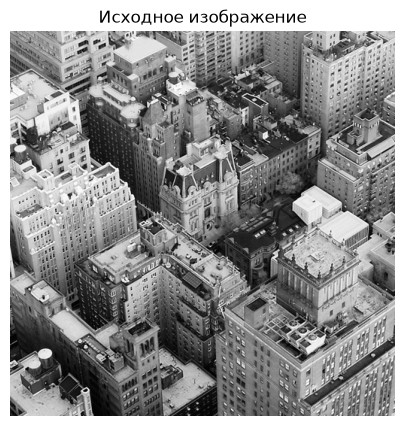

In [1]:
import numpy as np
import cv2 as cv
from matplotlib import pyplot as plt

image = cv.imread('image.jpg', cv.IMREAD_GRAYSCALE)

plt.figure(figsize=(5, 5))
plt.imshow(image, cmap='gray'); plt.title('Исходное изображение'); plt.axis('off')
plt.show()


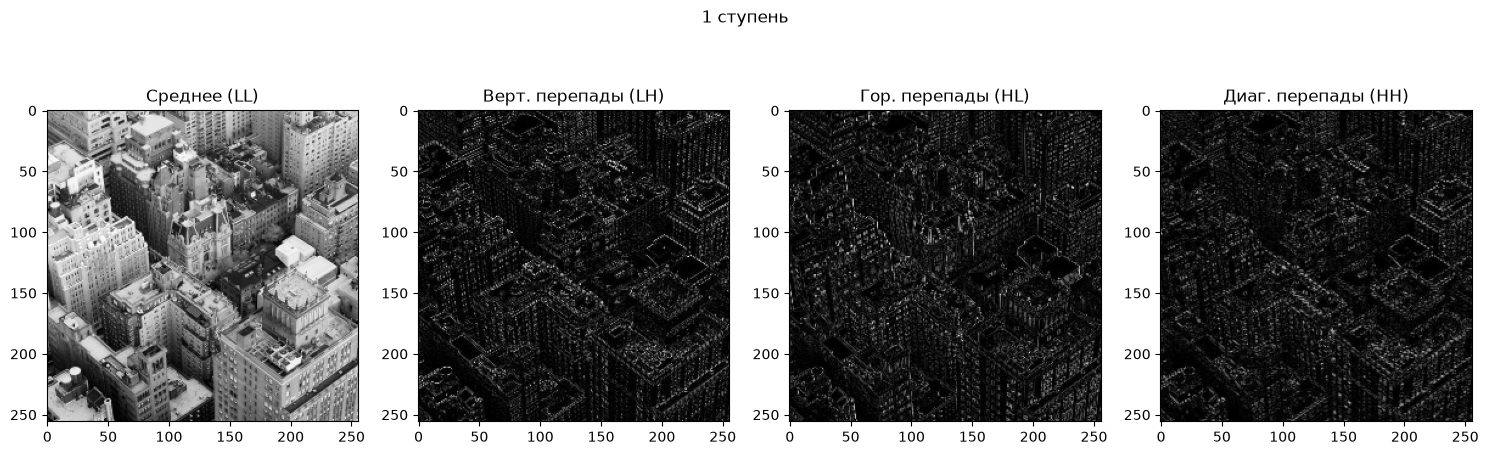

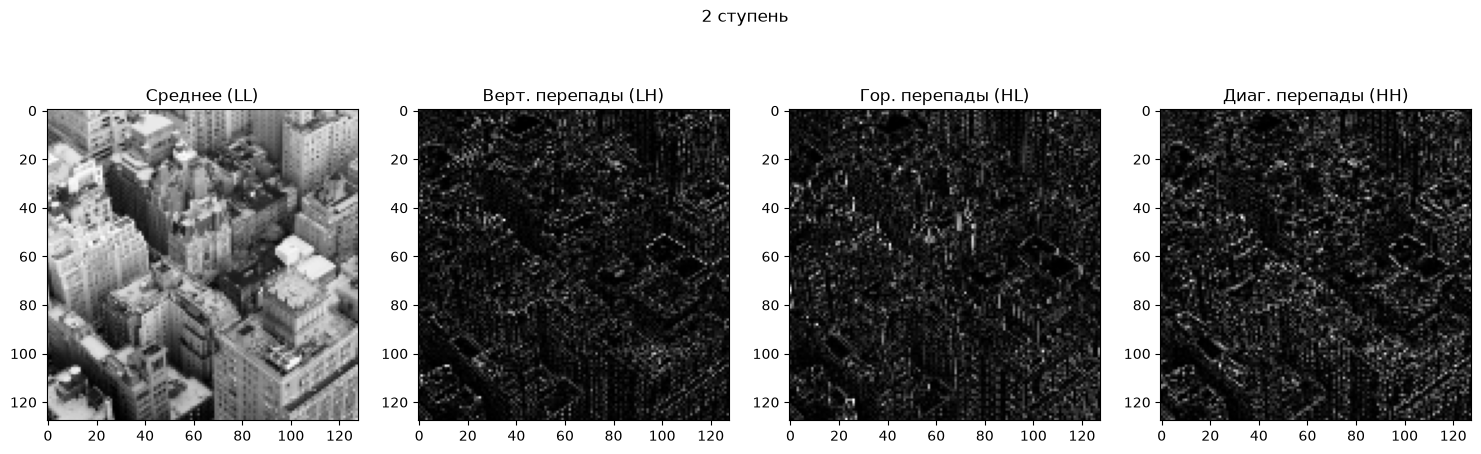

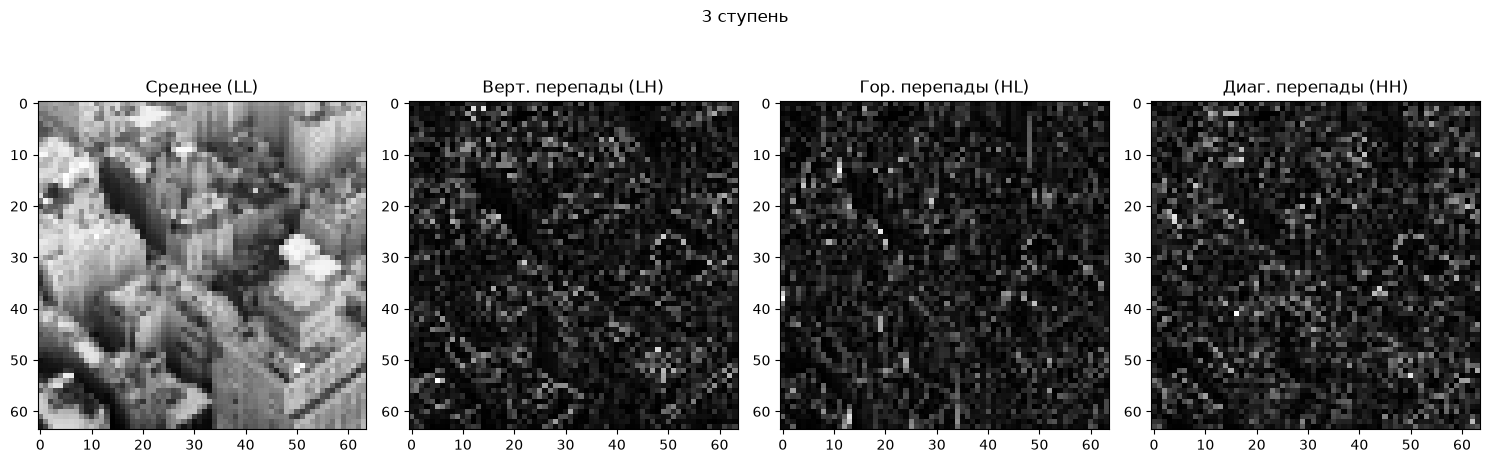

In [2]:
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt


def haar_step(image):
    block = np.asarray(image, dtype=np.float32)

    a = block[0::2, 0::2]
    b = block[0::2, 1::2]
    c = block[1::2, 0::2]
    d = block[1::2, 1::2]

    LL = (a + b + c + d) / 2
    LH = (a + b - c - d) / 2
    HL = (a - b + c - d) / 2
    HH = (a - b - c + d) / 2
    return LL, LH, HL, HH


def show_4_imgs(A11, A12, A21, A22, title=''):
    fig, ax = plt.subplots(1, 4, figsize=(15, 5))
    ax[0].imshow(np.abs(A11), cmap='gray'); ax[0].set_title('Среднее (LL)')
    ax[1].imshow(np.abs(A12), cmap='gray'); ax[1].set_title('Верт. перепады (LH)')
    ax[2].imshow(np.abs(A21), cmap='gray'); ax[2].set_title('Гор. перепады (HL)')
    ax[3].imshow(np.abs(A22), cmap='gray'); ax[3].set_title('Диаг. перепады (HH)')
    fig.suptitle(title)
    plt.tight_layout(); plt.show()

h, w = image.shape
image = image[:h - h % 8, :w - w % 8]

s1 = haar_step(image)
show_4_imgs(*s1, title='1 ступень')

s2 = haar_step(s1[0])
show_4_imgs(*s2, title='2 ступень')

s3 = haar_step(s2[0])
show_4_imgs(*s3, title='3 ступень')